# P0 · Sanity dei dati

Obiettivo: essere sicuri che i dati siano allineati e completi, e documentare i conteggi.

Questo notebook fa solo esplorazione e grafici. Il codice di training resta in `src/`.

## 0. Setup

In [1]:
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

SEED = 0
random.seed(SEED)
np.random.seed(SEED)

split = pd.read_csv(ROOT / "data/splits/split.csv")
print(split.shape)
split["split"].value_counts()

(19798, 8)


split
train    14772
val       2778
test      2248
Name: count, dtype: int64

In [2]:
import numpy as np

print("duplicati:", split["narration_id"].duplicated().sum())
print(split["split"].value_counts().reindex(["train", "val", "test"]))

video = np.load(ROOT / "data/features/timesformer_k400_8f/timesformer_k400_8f.npz")
print("video: righe", len(video["narration_id"]),
      "| mancanti:", (~split["narration_id"].isin(set(video["narration_id"]))).sum())

for enc in ["mpnet", "bert", "clip"]:
    text = np.load(ROOT / f"data/features/text/{enc}.npz")
    print(f"{enc}: righe", len(text["narration_id"]),
          "| mancanti:", (~split["narration_id"].isin(set(text["narration_id"]))).sum())


duplicati: 0
split
train    14772
val       2778
test      2248
Name: count, dtype: int64
video: righe 19798 | mancanti: 0
mpnet: righe 19798 | mancanti: 0
bert: righe 19798 | mancanti: 0
clip: righe 19798 | mancanti: 0


classi verbo presenti per split: {'train': 72, 'val': 54, 'test': 44}
classi nome presenti per split: {'train': 184, 'val': 117, 'test': 92}


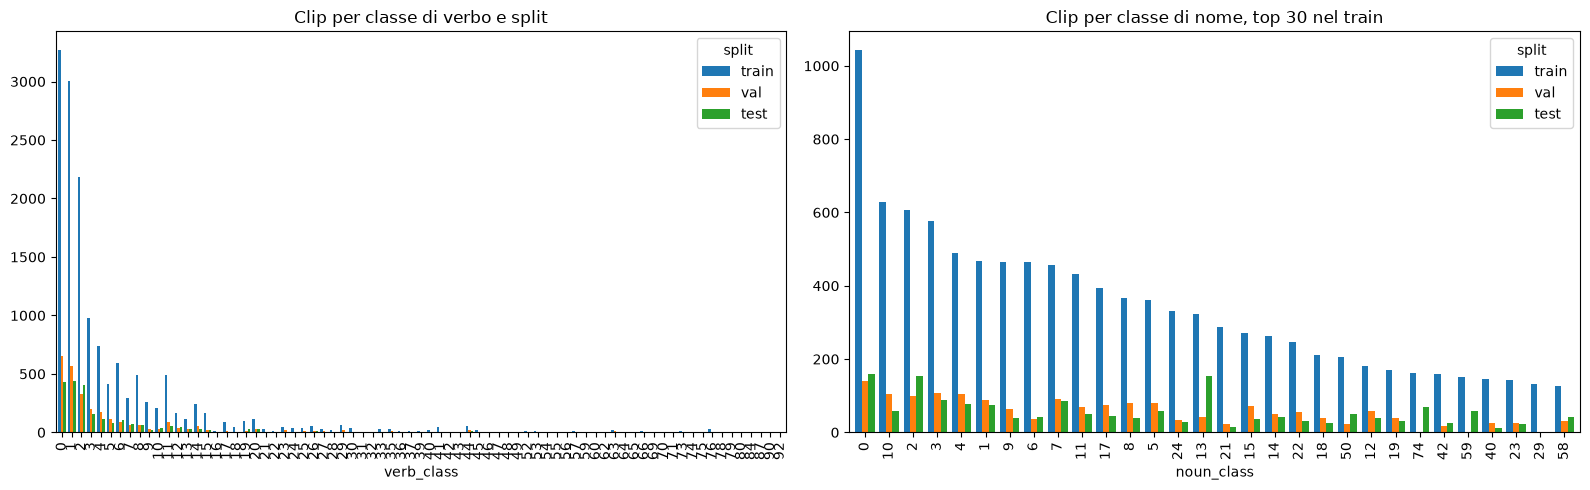

In [3]:
verbs = split.groupby(["verb_class", "split"]).size().unstack(1).reindex(columns=["train", "val", "test"]).fillna(0).astype(int)
nouns = split.groupby(["noun_class", "split"]).size().unstack(1).reindex(columns=["train", "val", "test"]).fillna(0).astype(int)

print("classi verbo presenti per split:", (verbs > 0).sum().to_dict())
print("classi nome presenti per split:", (nouns > 0).sum().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
verbs.plot.bar(ax=axes[0], width=0.8)
axes[0].set_title("Clip per classe di verbo e split")
axes[0].set_xlabel("verb_class")

top_nouns = nouns.sort_values("train", ascending=False).head(30)
top_nouns.plot.bar(ax=axes[1], width=0.8)
axes[1].set_title("Clip per classe di nome, top 30 nel train")
axes[1].set_xlabel("noun_class")

plt.tight_layout()
plt.savefig(ROOT / "figures/p0_verbi_nomi_per_split.png", dpi=150)
plt.show()


In [4]:
combo = ["verb_class", "noun_class"]
seen = set(map(tuple, split.loc[split["split"] == "train", combo].values))

for s in ["val", "test"]:
    part = split[split["split"] == s]
    nuova = part[combo].apply(tuple, axis=1).map(lambda c: c not in seen)
    n_combo = part[combo].drop_duplicates().shape[0]
    n_nuove = part.loc[nuova, combo].drop_duplicates().shape[0]
    print(f"{s}: combinazioni {n_combo}, assenti dal train {n_nuove}, clip nuove {nuova.sum()} su {len(part)}")

test = split[split["split"] == "test"]
nuova = test[combo].apply(tuple, axis=1).map(lambda c: c not in seen)
tabella = test.loc[nuova].groupby(combo).size().rename("clip").reset_index()
tabella.to_csv(ROOT / "experiments/logs/p0_combinazioni_nuove_test.csv", index=False)
print(tabella.sort_values("clip", ascending=False).head(10))


val: combinazioni 560, assenti dal train 139, clip nuove 274 su 2778
test: combinazioni 392, assenti dal train 63, clip nuove 127 su 2248
    verb_class  noun_class  clip
23           7          30     9
30          11          30     7
10           2          59     7
25           7         120     6
28          10          32     5
27          10          30     5
15           5          30     4
16           5          43     4
51          19          30     4
46          15          59     3


In [5]:
import importlib
import json
import platform

info = json.load(open(ROOT / "data/splits/split_info.json"))

print("python", platform.python_version())
for m in ["numpy", "pandas", "sklearn", "torch"]:
    try:
        print(m, importlib.import_module(m).__version__)
    except ImportError:
        print(m, "non installato")

print("seed split:", info["seed"], "| val_frac:", info["val_frac"], "| sessioni di val:", len(info["val_sessions"]))
print("seed baseline zero-shot: 42 (src/evaluation/baseline_zero_shot.py)")
print("seed notebook:", SEED)


python 3.12.0
numpy 2.5.4
pandas 3.1.0
sklearn 1.9.1
torch 2.14.1
seed split: 0 | val_frac: 0.15 | sessioni di val: 10
seed baseline zero-shot: 42 (src/evaluation/baseline_zero_shot.py)
seed notebook: 0


## Riepilogo P0

**Allineamento.** Nessun `narration_id` duplicato. Tutte le clip di `split.csv` sono presenti nelle feature video e nei tre encoder di testo.

**Conteggi per split.** train 14.772, val 2.778, test 2.248.

**Classi.** Verbi presenti: 72 nel train, 54 nel val, 44 nel test. Nomi presenti: 184 nel train, 117 nel val, 92 nel test. La distribuzione è molto sbilanciata: i primi due verbi hanno circa 3.000 clip ciascuno nel train.

**Combinazioni verbo/nome nuove.** Val: 139 combinazioni su 560 assenti dal train, 274 clip su 2.778. Test: 63 combinazioni su 392 assenti dal train, 127 clip su 2.248. Tabella completa in `experiments/logs/p0_combinazioni_nuove_test.csv`.

**Seed e versioni.** Seed split 0, baseline 42, notebook 0. Python 3.12.0, numpy 2.5.4, pandas 3.1.0, sklearn 1.9.1, torch 2.14.1.

